## Image Classification using Logistic Regression and SVM with Feature Engineering

1. **Load and visualize the dataset:** Convert images to grayscale and resize them; flatten images for the raw-pixel models.
2. **Train Logistic Regression on raw pixels:** Establish a baseline using flattened pixel values.
3. **Extract HOG features:** Compute Histogram of Oriented Gradients features from the resized images.
4. **Train Logistic Regression on HOG features:** Compare its performance with the raw-pixel baseline.
5. **Train SVM classifiers on raw pixels and HOG features:** Compare SVM performance with Logistic Regression and evaluate the effect of HOG features.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from skimage.feature import hog
from sklearn.metrics import confusion_matrix

c:\Users\PC\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been deprecated
  "class": algorithms.Blowfish,


### Helper functions

In [2]:
def imshow(image, title=None):
    plt.axis('off')
    plt.title(title)
    plt.imshow(image, 'gray')
    plt.show()
def showGridImage(images, labels, gsize=5,title=None):
    '''
    Function shows Multiple images.
    params: 
    images--> [Req] array of images flatten to 100*100
    labels --> [Req] array of labels (image class)
    gsize --> [opt, default=5] size for the grid gsize x gsize
    title --> [opt, default=None] title for the grid
    '''
    selected_indices = np.random.choice(len(images), size=gsize*gsize, replace=False)

    # Create a 5x5 grid for subplots
    fig, axes = plt.subplots(gsize,gsize, figsize=(10, 10))
    for i, ax in enumerate(axes.ravel()):
        index = selected_indices[i]
        image = images[index]
        label = labels[index]
        ax.imshow(image.reshape(100,100), 'gray')
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f"Image {classes[label]}")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

### Loading the data

In [3]:
mainPath = './dataset/'
classes = os.listdir(mainPath)

In [4]:
classes

['Cars', 'Cricket ball', 'Ice cream cone']

In [5]:
images = []
labels = []
for i in classes:
    clsPath = os.path.join(mainPath,i)
    for imgName in os.listdir(clsPath):
        imgPath = os.path.join(clsPath, imgName)
        image = cv2.imread(imgPath, 0)
        image = cv2.resize(image, (100,100))
        images.append(image.flatten())
        label = classes.index(i)
        labels.append(label)

In [9]:
len(labels)

987

### Converting to numpy arrays

In [10]:
images = np.array(images)
labels = np.array(labels)

In [11]:
type(images)

numpy.ndarray

In [12]:
data = pd.DataFrame(images)
data

,0,1,2,3,4,5,6,7,8,9,...,9990,9991,9992,9993,9994,9995,9996,9997,9998,9999
0,255,255,255,255,255,255,255,255,255,255,...,255,255,255,255,255,255,255,255,255,255
1,183,185,186,186,190,192,195,199,201,202,...,83,83,85,85,86,86,84,85,84,83
2,43,65,64,49,48,53,50,36,44,46,...,145,149,158,156,162,158,146,151,153,149
3,180,180,174,176,173,172,160,65,36,37,...,113,128,127,117,114,113,108,114,116,122
4,103,21,15,17,49,112,108,119,78,14,...,144,121,136,133,151,148,122,144,137,141
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
982,117,116,115,117,117,117,117,116,116,117,...,96,95,95,94,94,94,93,92,92,91
983,97,96,97,100,109,123,136,147,153,161,...,170,166,163,159,155,153,152,150,150,148
984,255,255,255,255,255,255,255,255,255,255,...,255,255,255,255,255,255,255,255,255,255
985,255,255,255,255,255,255,255,255,255,255,...,255,255,255,255,255,255,255,255,255,255


### showing few random images from dataset

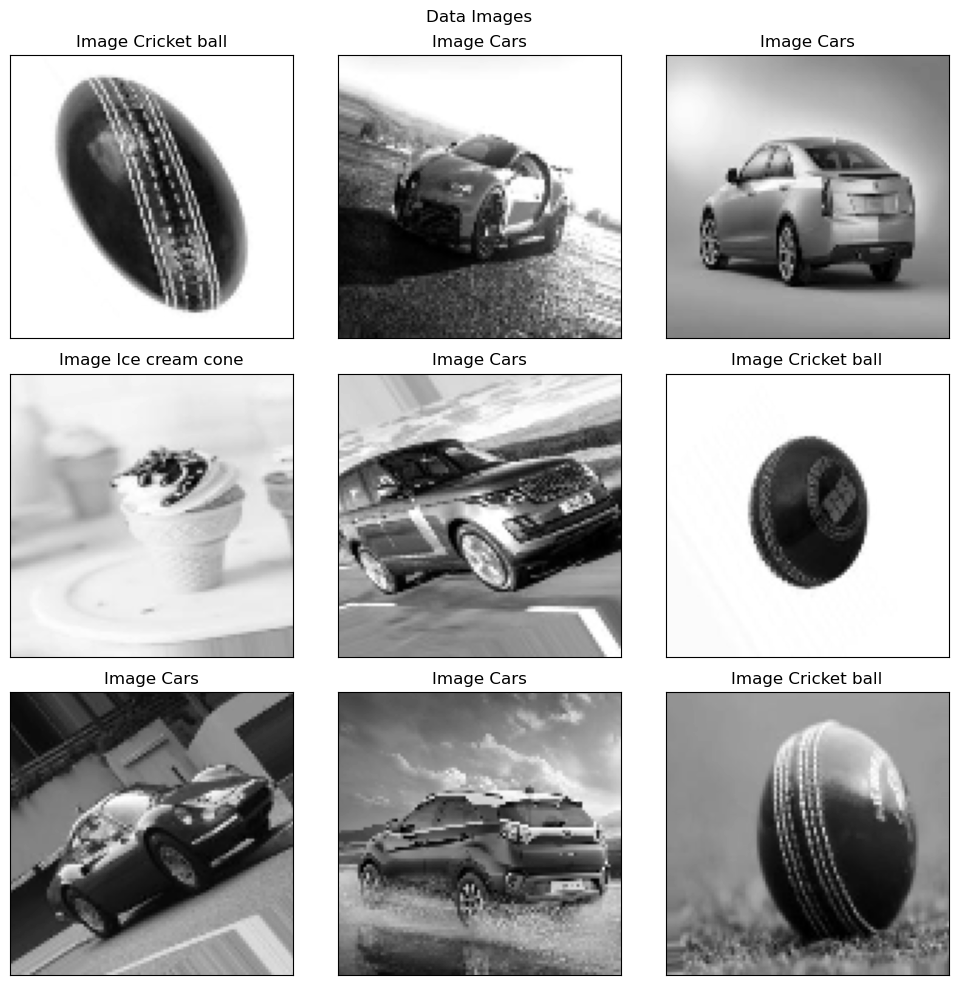

In [14]:
showGridImage(images, labels , 3, 'Data Images')

### Splitting the dataset into train and test data
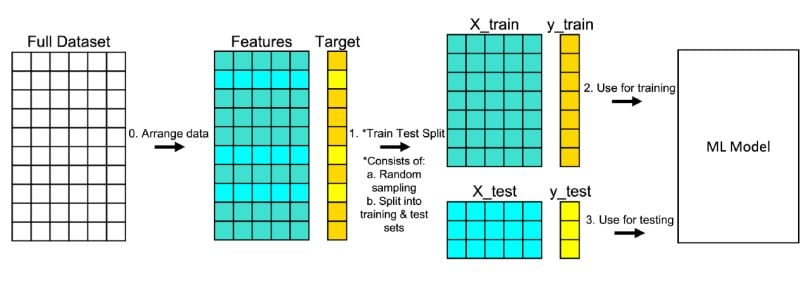

In [15]:
xTrain, xTest, yTrain, yTest = train_test_split(images, labels, test_size=0.2, random_state=0)

### Fitting the ML Model (Logistic Regression)
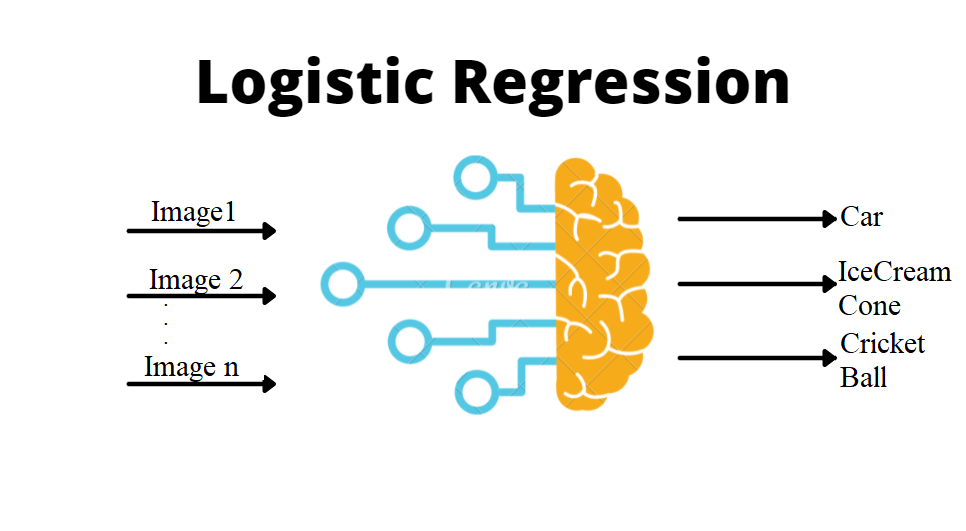

In [16]:
logisticReg = LogisticRegression(max_iter=1000)
logisticReg.fit(xTrain, yTrain)

LogisticRegression(max_iter=1000)

### Prediction on Test Data

In [17]:
predsClasses = logisticReg.predict(xTest)

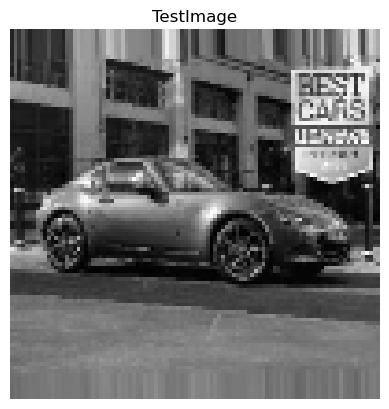

In [24]:
imshow(xTest[30].reshape(100,100), 'TestImage')
ModelPrediction = logisticReg.predict([xTest[30]])

In [25]:
classes[ModelPrediction[0]]

'Cars'

### Evaluating the model
    1. Train Accuracy
    2. Test Accuracy

In [27]:
trainAccuracy = logisticReg.score(xTrain, yTrain)
testAccuracy = logisticReg.score(xTest,yTest)
print(f'Training Accuracy: {trainAccuracy*100:.2f}%')
print(f'Test Accuracy: {testAccuracy*100:.2f}%')

Training Accuracy: 100.00%
Test Accuracy: 79.80%


### Confusion Matrix
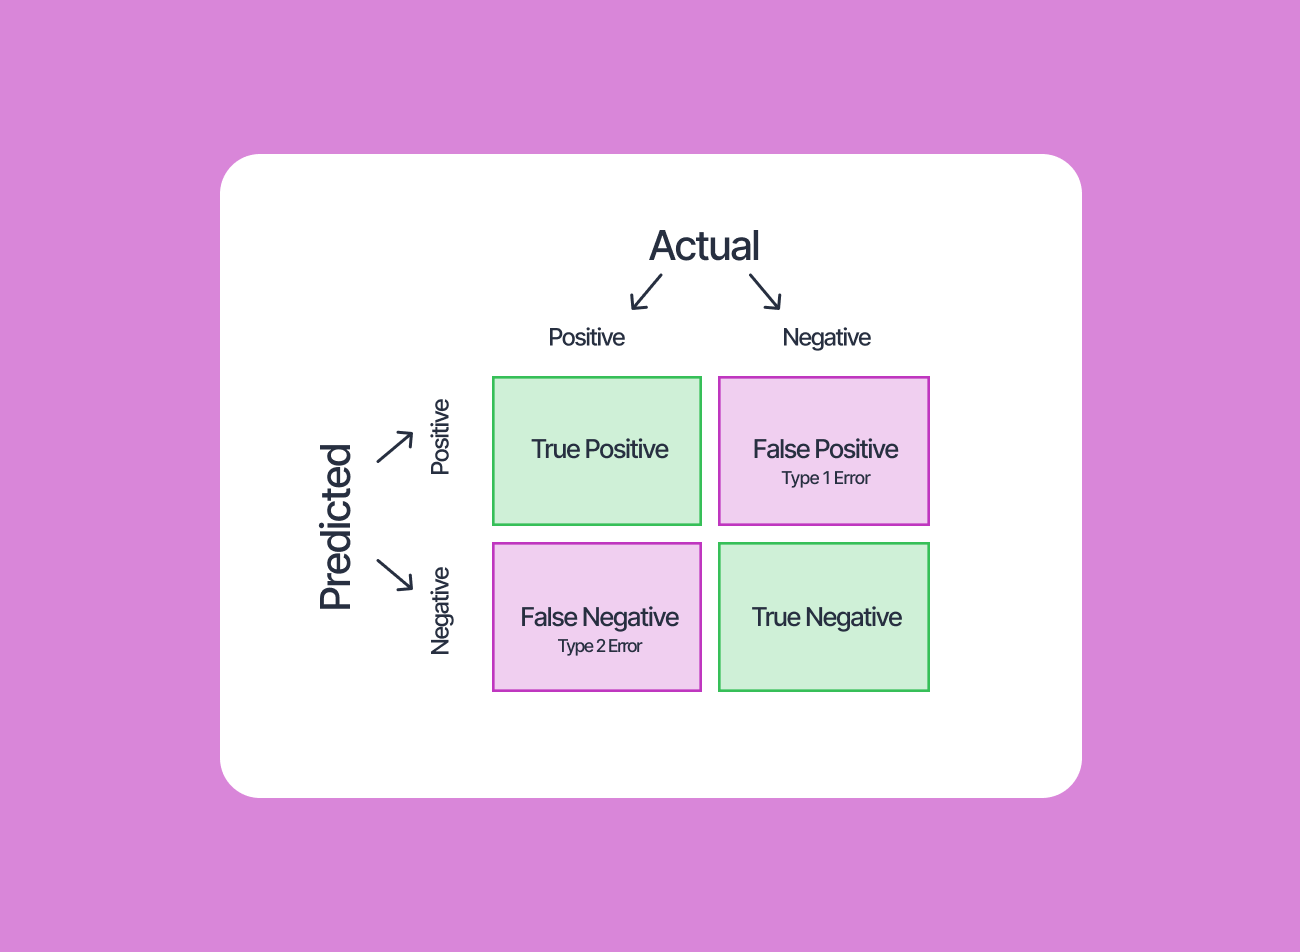

<Axes: >

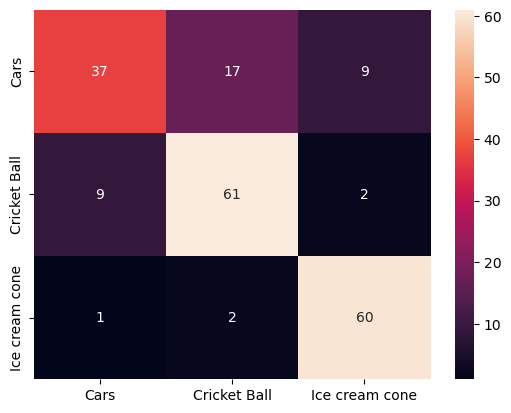

In [28]:
class_names = ['Cars', 'Cricket Ball', 'Ice cream cone']
cmLogistic = confusion_matrix(yTest, predsClasses)
sns.heatmap(cmLogistic, annot=True, xticklabels=class_names, yticklabels=class_names, fmt='d')

### Showing images with model predicted Class 

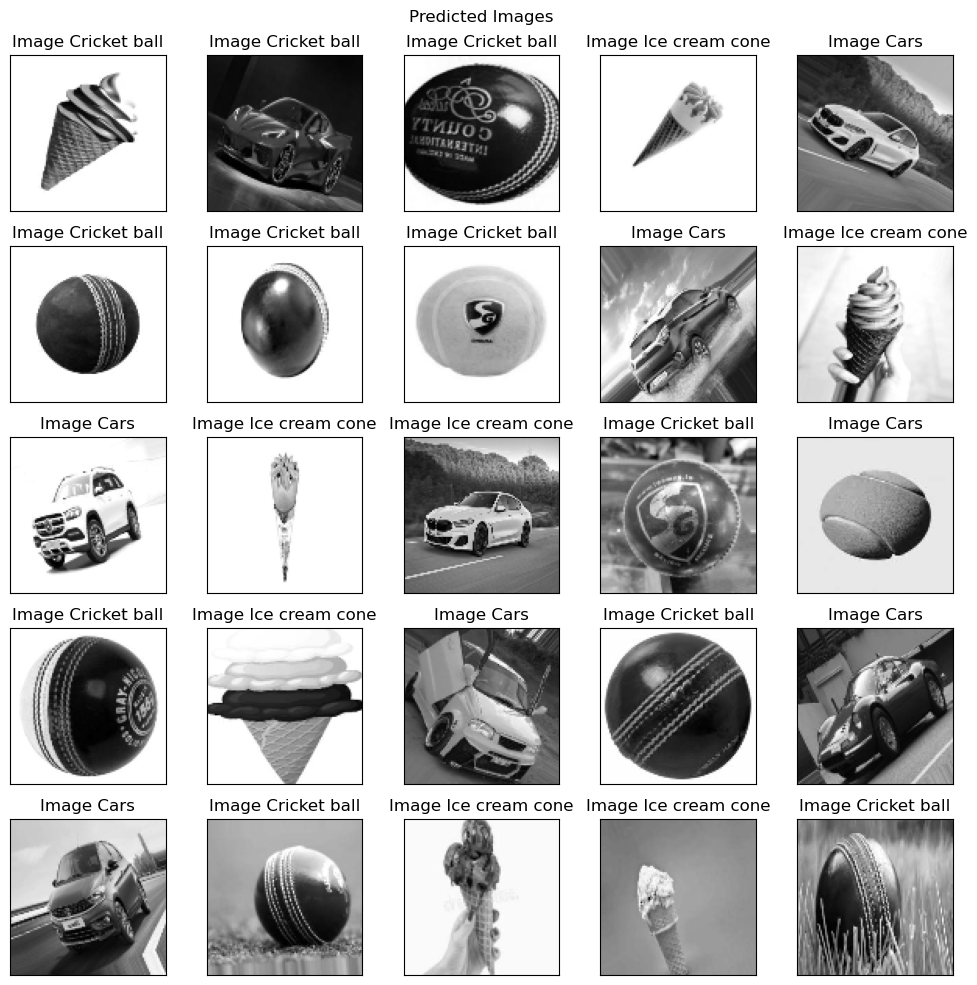

In [29]:
showGridImage(xTest, predsClasses, 5, 'Predicted Images')

---

### Using the hog feature descriptor for feature extraction

### Hog Features Descriptor
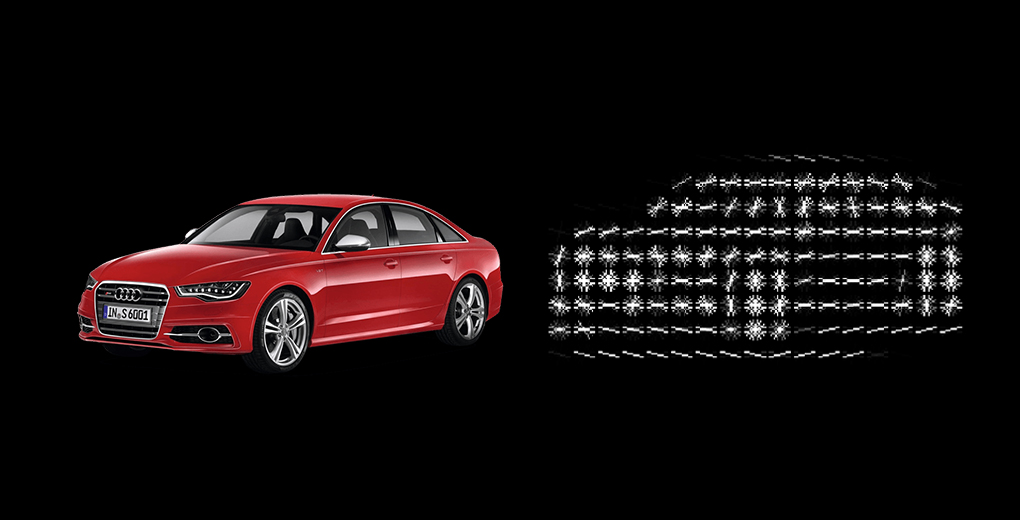
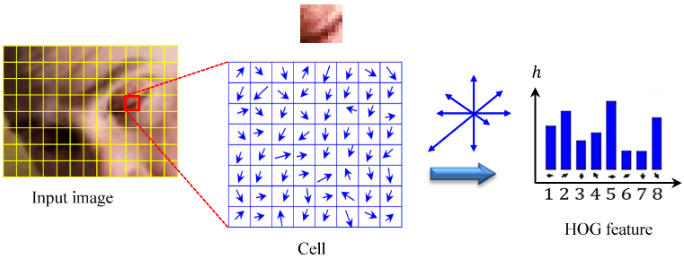

In [30]:
mainPath = './dataset/'
classes = os.listdir(mainPath)
hogImages = []
hogFeatures = []
labels = []
for i in classes:
    clsPath = os.path.join(mainPath,i)
    for imgName in os.listdir(clsPath):
        imgPath = os.path.join(clsPath, imgName)
        image = cv2.imread(imgPath, 0)
        image = cv2.resize(image, (100,100))
        features, hogImage = hog(image, visualize=True)
        hogImages.append(hogImage)
        hogFeatures.append(features)
        label = classes.index(i)
        labels.append(label)

In [31]:
hogFeatures = np.array(hogFeatures)
labels = np.array(labels)
hogImages = np.array(hogImages)

### Visualizing HOG images

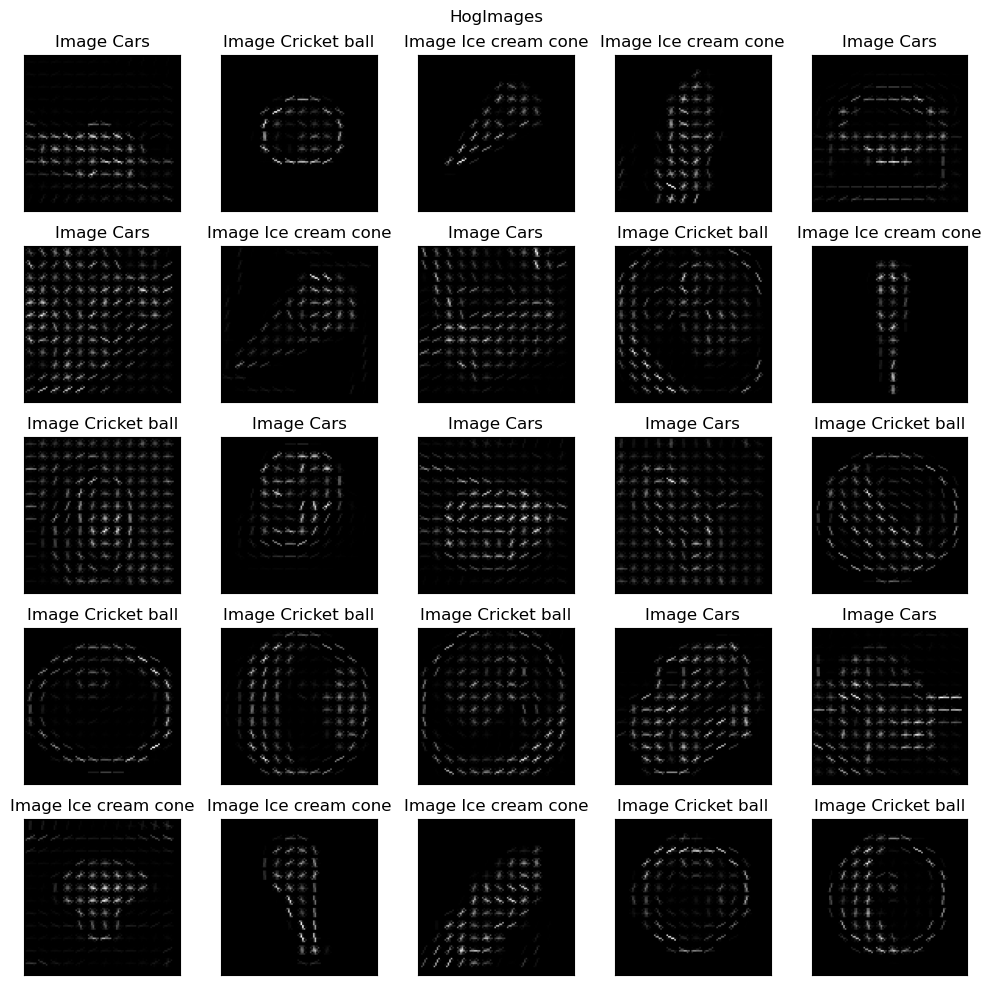

In [32]:
showGridImage(hogImages, labels, title='HogImages')

In [33]:
xTrain, xTest, yTrain, yTest = train_test_split(hogFeatures, labels, test_size=0.2, random_state=42)
hogTrainImages, hogTestImages, hogTrainLabels, hogTestLabels = train_test_split(hogImages, labels, test_size=0.2, random_state=42)

### Fitting Logistic Regression on HOG features

In [34]:
logisticReg = LogisticRegression(max_iter=1000)
logisticReg.fit(xTrain, yTrain)

LogisticRegression(max_iter=1000)

In [35]:
predsClasses = logisticReg.predict(xTest)

In [36]:
trainAccuracy = logisticReg.score(xTrain, yTrain)
testAccuracy = logisticReg.score(xTest,yTest)
print(f'Training Accuracy: {trainAccuracy*100:.2f}%')
print(f'Test Accuracy: {testAccuracy*100:.2f}%')

Training Accuracy: 100.00%
Test Accuracy: 96.97%


### Showing predictions

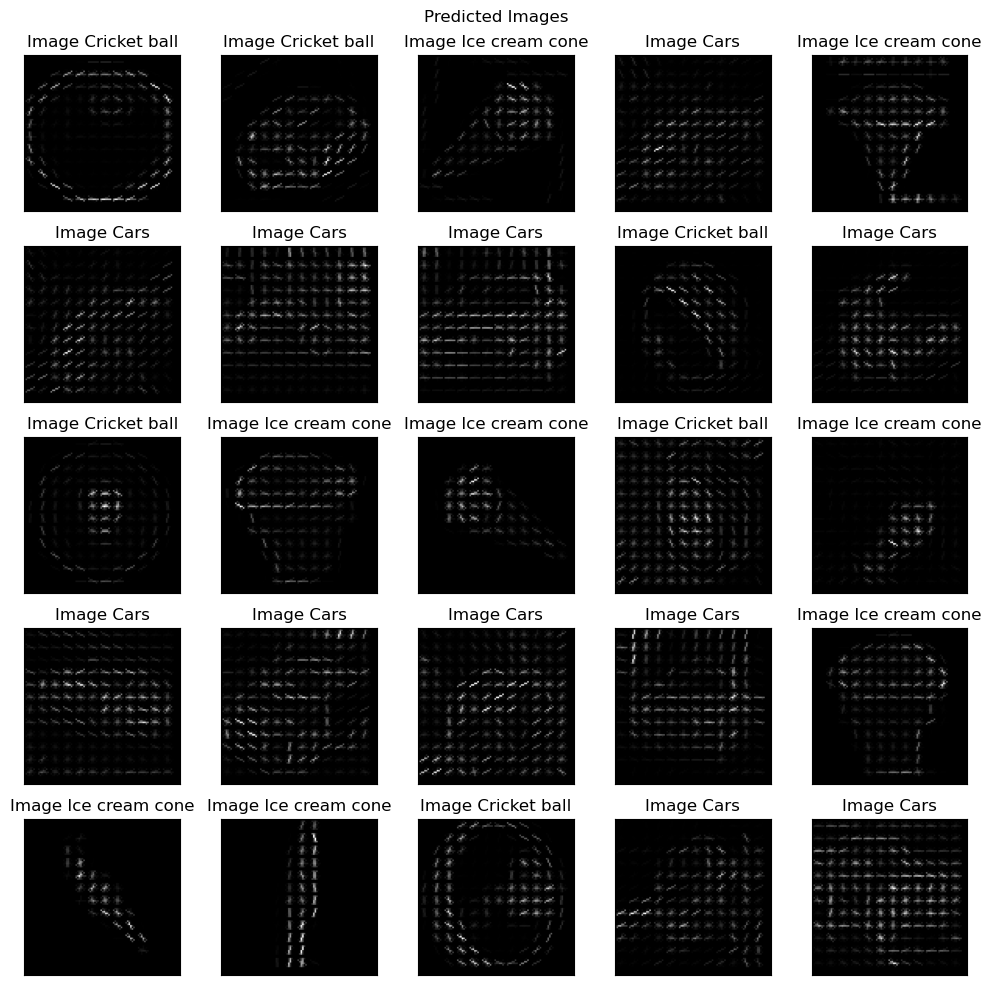

In [37]:
showGridImage(hogTestImages, predsClasses, 5,'Predicted Images')

<Axes: >

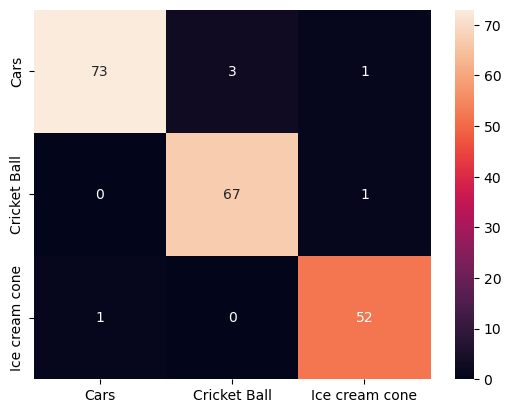

In [38]:
class_names = ['Cars', 'Cricket Ball', 'Ice cream cone']
cmLogistic_hog = confusion_matrix(yTest, predsClasses)
sns.heatmap(cmLogistic_hog, annot=True, xticklabels=class_names, yticklabels=class_names, fmt='d')

---

## Support Vector Machine

In [39]:
mainPath = './dataset/'
classes = os.listdir(mainPath)
images = []
labels = []
for i in classes:
    clsPath = os.path.join(mainPath,i)
    for imgName in os.listdir(clsPath):
        imgPath = os.path.join(clsPath, imgName)
        image = cv2.imread(imgPath, 0)
        image = cv2.resize(image, (100,100))
        images.append(image.flatten())
        label = classes.index(i)
        labels.append(label)

In [40]:
images = np.array(images)
labels = np.array(labels)

In [41]:
xTrain, xTest, yTrain, yTest = train_test_split(images, labels, test_size=0.2, random_state=42)

### Fitting Support Vector Classifier on images

In [42]:
SVMClassifier = SVC()
SVMClassifier.fit(xTrain, yTrain)

SVC()

In [43]:
predsClasses = SVMClassifier.predict(xTest)

In [44]:
trainAccuracy = SVMClassifier.score(xTrain, yTrain)
testAccuracy = SVMClassifier.score(xTest,yTest)
print(f'Training Accuracy: {trainAccuracy*100:.2f}%')
print(f'Test Accuracy: {testAccuracy*100:.2f}%')

Training Accuracy: 97.34%
Test Accuracy: 92.93%


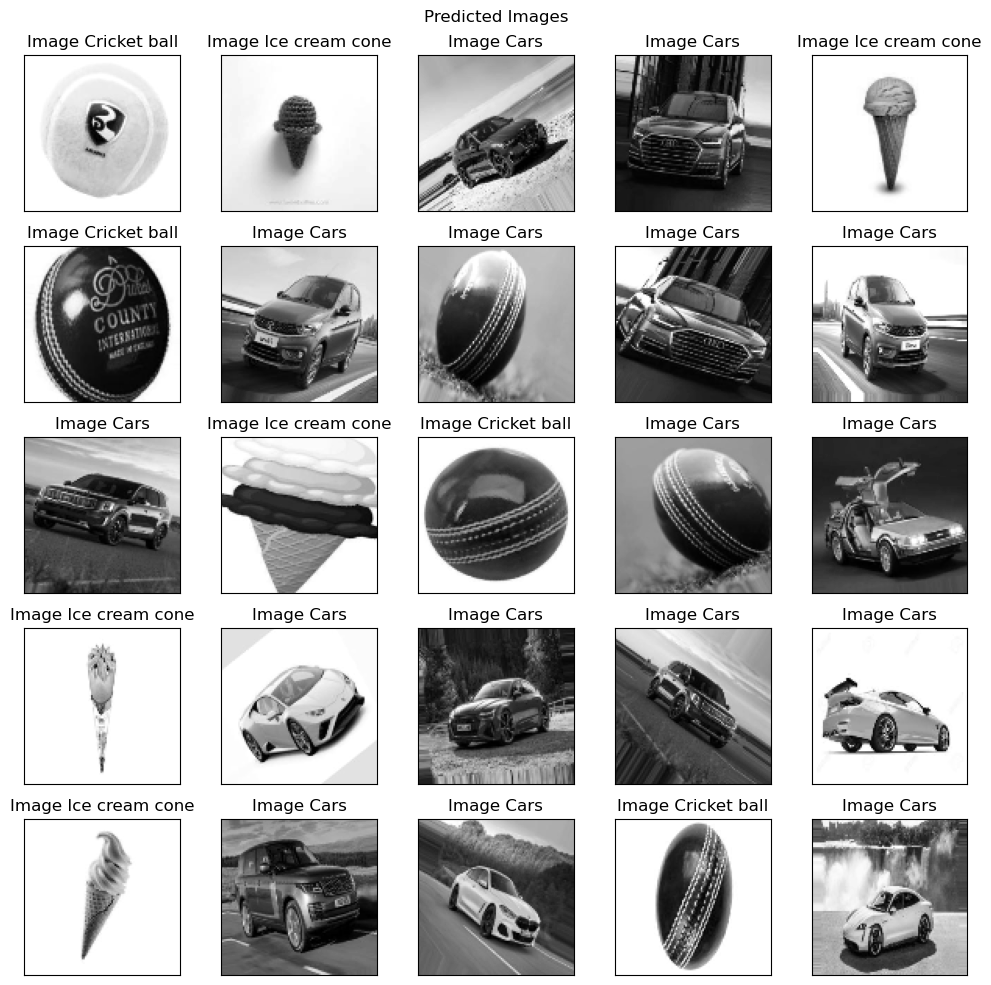

In [45]:
showGridImage(xTest, predsClasses, 5,'Predicted Images')

<Axes: >

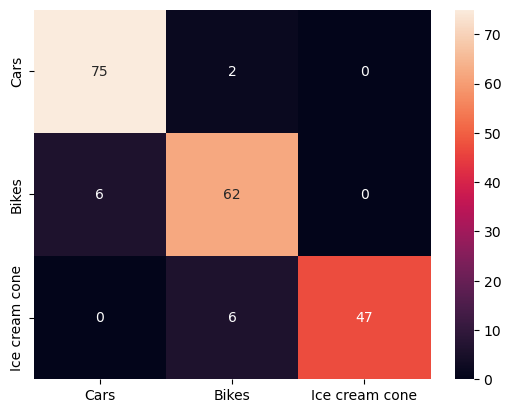

In [46]:
class_names = ['Cars', 'Bikes', 'Ice cream cone']
cmSvm = confusion_matrix(yTest, predsClasses)
sns.heatmap(cmSvm, annot=True, xticklabels=class_names, yticklabels=class_names, fmt='d')

---

In [47]:
mainPath = './dataset/'
classes = os.listdir(mainPath)
hogImages = []
hogFeatures = []
labels = []
for cls in classes:
    clsPath = os.path.join(mainPath,cls)
    for imgName in os.listdir(clsPath):
        imgPath = os.path.join(clsPath, imgName)
        image = cv2.imread(imgPath, 0)
        image = cv2.resize(image, (100,100))
        features, hogImage = hog(image, visualize=True)
        hogImages.append(hogImage)
        hogFeatures.append(features)
        label = classes.index(cls)
        labels.append(label)

In [48]:
images = np.array(images)
labels = np.array(labels)

In [49]:
xTrain, xTest, yTrain, yTest = train_test_split(hogFeatures, labels, test_size=0.2, random_state=42)
hogTrainImages, HogTestImages, hogTrainLabels, hogTestLabels = train_test_split(hogImages, labels, test_size=0.2, random_state=42)

### Fitting Support Vector Classifier on HOG features

In [50]:
SVMClassifier = SVC()
SVMClassifier.fit(xTrain, yTrain)

SVC()

In [51]:
predsClasses = SVMClassifier.predict(xTest)

In [53]:
trainAccuracy = SVMClassifier.score(xTrain, yTrain)
testAccuracy = SVMClassifier.score(xTest,yTest)
print(f'Training Accuracy: {trainAccuracy*100:.2f}%')
print(f'Test Accuracy: {testAccuracy*100:.2f}%')

Training Accuracy: 99.87%
Test Accuracy: 97.47%


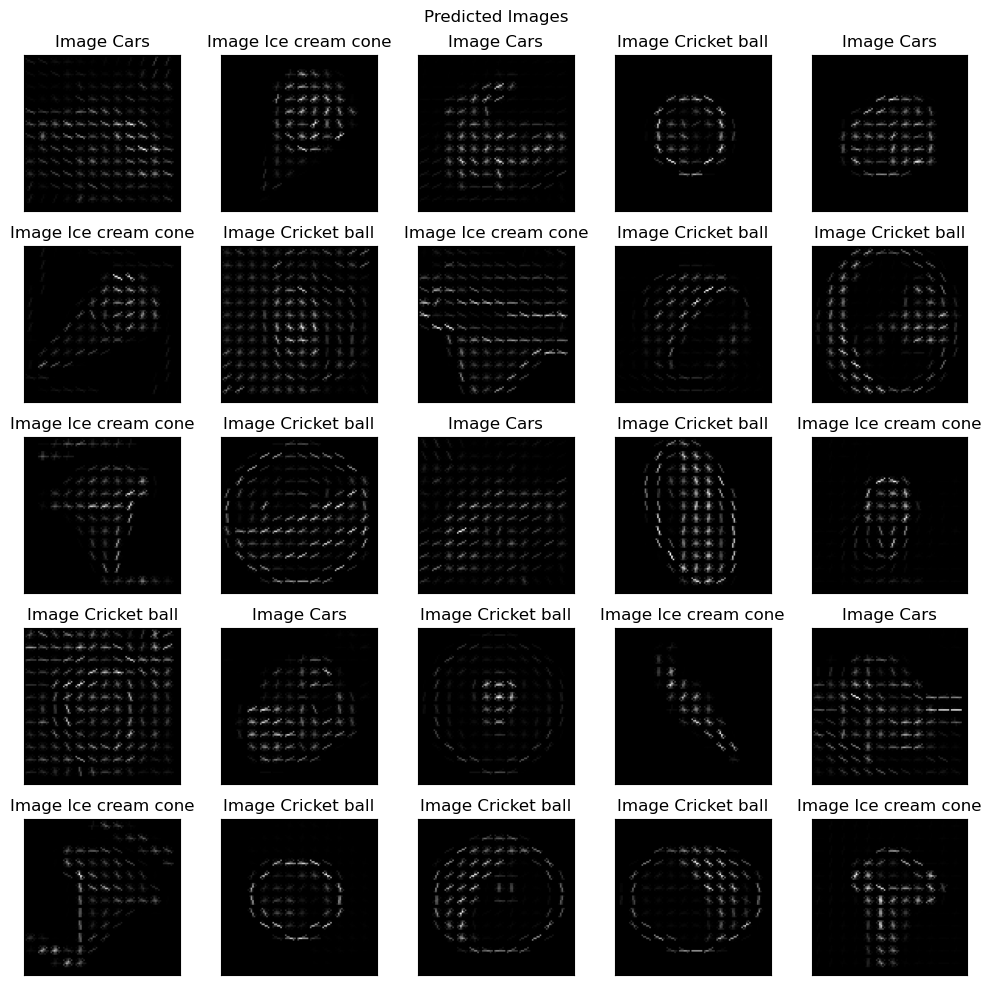

In [54]:
showGridImage(HogTestImages, predsClasses, 5,'Predicted Images')

<Axes: >

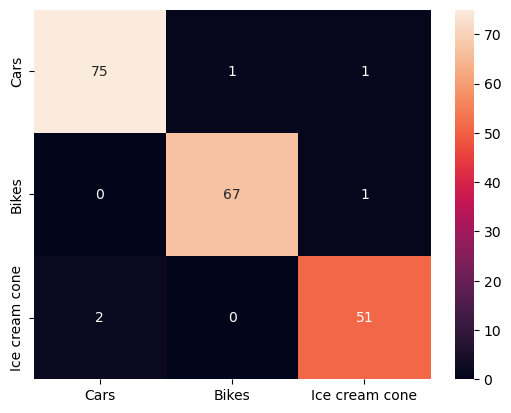

In [55]:
class_names = ['Cars', 'Bikes', 'Ice cream cone']
cmSvm_hog = confusion_matrix(yTest, predsClasses)
sns.heatmap(cmSvm_hog, annot=True, xticklabels=class_names, yticklabels=class_names, fmt='d')

---

# Model Comparison Table

| **Model** | **Feature Extractor (HOG)** | **Training Accuracy (%)** | **Test Accuracy (%)** |
|---|---|---:|---:|
| Logistic Regression (Raw Data) — Run 1 | ❌ No | 100.00 | 79.80 |
| Logistic Regression (HOG Features) — Run 1 | ✅ Yes | 100.00 | 96.97 |
| SVM (Raw Data) — Run 2 | ❌ No | 97.34 | 92.93 |
| SVM (HOG Features) — Run 2 | ✅ Yes | 99.87 | 97.47 |

## **Observations:**
1. **HOG feature extraction improves test accuracy** in both comparisons: from 79.80% to 96.97% for Logistic Regression, and from 92.93% to 97.47% for SVM.
2. **The raw-data Logistic Regression model shows a larger train–test gap**, with 100.00% training accuracy and 79.80% test accuracy. HOG models have smaller gaps, suggesting better generalization in these runs.

## Save the best model

In [56]:
import joblib

best_model = SVMClassifier
best_model_path = "best_model.pkl"
joblib.dump(best_model, best_model_path)

['best_model.pkl']

---